# Day 075 | Variational Autoencoders (VAE)

## 100 Days of ML for Geotechnical Engineering
**Phase:** Deep Learning

**Author:** Ripon Chandra Malo

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| VAE | Autoencoder with probabilistic latent space | Generating plausible new soil profiles |
| KL divergence | Regularizes latent space toward a prior | Ensuring smooth, continuous soil property space |
| Reparameterization trick | Enables backprop through sampling | Making random generation trainable |
| Generative model | Can sample new, realistic data | Creating synthetic soil profiles for Monte Carlo |
| ELBO loss | Reconstruction + KL divergence | Balancing accuracy and generative quality |

---

## Our Geotechnical Problem

Site investigations are expensive. We have **100 soil samples** with correlated properties,
but need **thousands of samples** for reliability analysis (Monte Carlo simulation).

We will:
1. Train a VAE on real (synthetic) soil data to learn the distribution
2. **Generate new, realistic soil profiles** that respect property correlations
3. Compare generated samples against the training distribution

---

In [1]:
# ───────────────────────────────────────────────────────
# IMPORTS
# ───────────────────────────────────────────────────────

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.5.1


## Part 1: Generating Correlated Soil Property Data

Real soil properties are correlated. For example:
- Higher moisture content correlates with lower density
- Higher plasticity index correlates with higher compression index
- Higher fines content correlates with lower permeability

A simple multivariate Gaussian cannot always capture these non-linear correlations.
A VAE can learn them.

---

In [2]:
# ───────────────────────────────────────────────────────
# GENERATE CORRELATED SOIL PROPERTY DATA
# ───────────────────────────────────────────────────────

def generate_soil_profiles(n_samples=200, seed=42):
    """
    Generate soil profiles with realistic correlations.
    
    Features: [moisture_content, dry_density, liquid_limit,
               plasticity_index, fines_content, Cc]
    """
    np.random.seed(seed)
    
    # Start from base random variables
    z1 = np.random.randn(n_samples)  # clay content driver
    z2 = np.random.randn(n_samples)  # density driver
    z3 = np.random.randn(n_samples)  # noise
    
    # Build correlated properties
    moisture = 35 + 12 * z1 + 3 * z3  # high clay -> high moisture
    dry_density = 16.5 - 1.5 * z1 + 0.8 * z2  # high clay -> low density
    liquid_limit = 45 + 15 * z1 + 4 * z3  # high clay -> high LL
    plasticity_index = 20 + 10 * z1 + 2 * z3  # high clay -> high PI
    fines_content = 60 + 15 * z1 + 5 * z3  # high clay -> high fines
    Cc = 0.3 + 0.15 * z1 + 0.03 * z3  # high clay -> high Cc
    
    # Add non-linear relationships
    Cc = Cc + 0.05 * np.maximum(0, moisture - 40)  # extra compression for very wet soils
    
    data = np.column_stack([moisture, dry_density, liquid_limit,
                           plasticity_index, fines_content, Cc])
    
    # Clip to realistic ranges
    data[:, 0] = np.clip(data[:, 0], 10, 70)    # moisture
    data[:, 1] = np.clip(data[:, 1], 12, 20)    # density
    data[:, 2] = np.clip(data[:, 2], 15, 85)    # LL
    data[:, 3] = np.clip(data[:, 3], 2, 50)     # PI
    data[:, 4] = np.clip(data[:, 4], 10, 98)    # fines
    data[:, 5] = np.clip(data[:, 5], 0.02, 0.9) # Cc
    
    return data

feature_names = ['Moisture (%)', 'Dry Density (kN/m3)', 'LL (%)',
                 'PI (%)', 'Fines (%)', 'Cc']

soil_data = generate_soil_profiles(n_samples=200)
print(f"Generated {soil_data.shape[0]} soil profiles with {soil_data.shape[1]} properties")
print(f"\nProperty statistics:")
for i, name in enumerate(feature_names):
    print(f"  {name:<22s}: mean={soil_data[:, i].mean():.2f}, std={soil_data[:, i].std():.2f}")

Generated 200 soil profiles with 6 properties

Property statistics:
  Moisture (%)          : mean=34.27, std=11.08
  Dry Density (kN/m3)   : mean=16.63, std=1.53
  LL (%)                : mean=44.06, std=13.79
  PI (%)                : mean=19.48, std=9.11
  Fines (%)             : mean=58.92, std=14.01
  Cc                    : mean=0.36, std=0.25


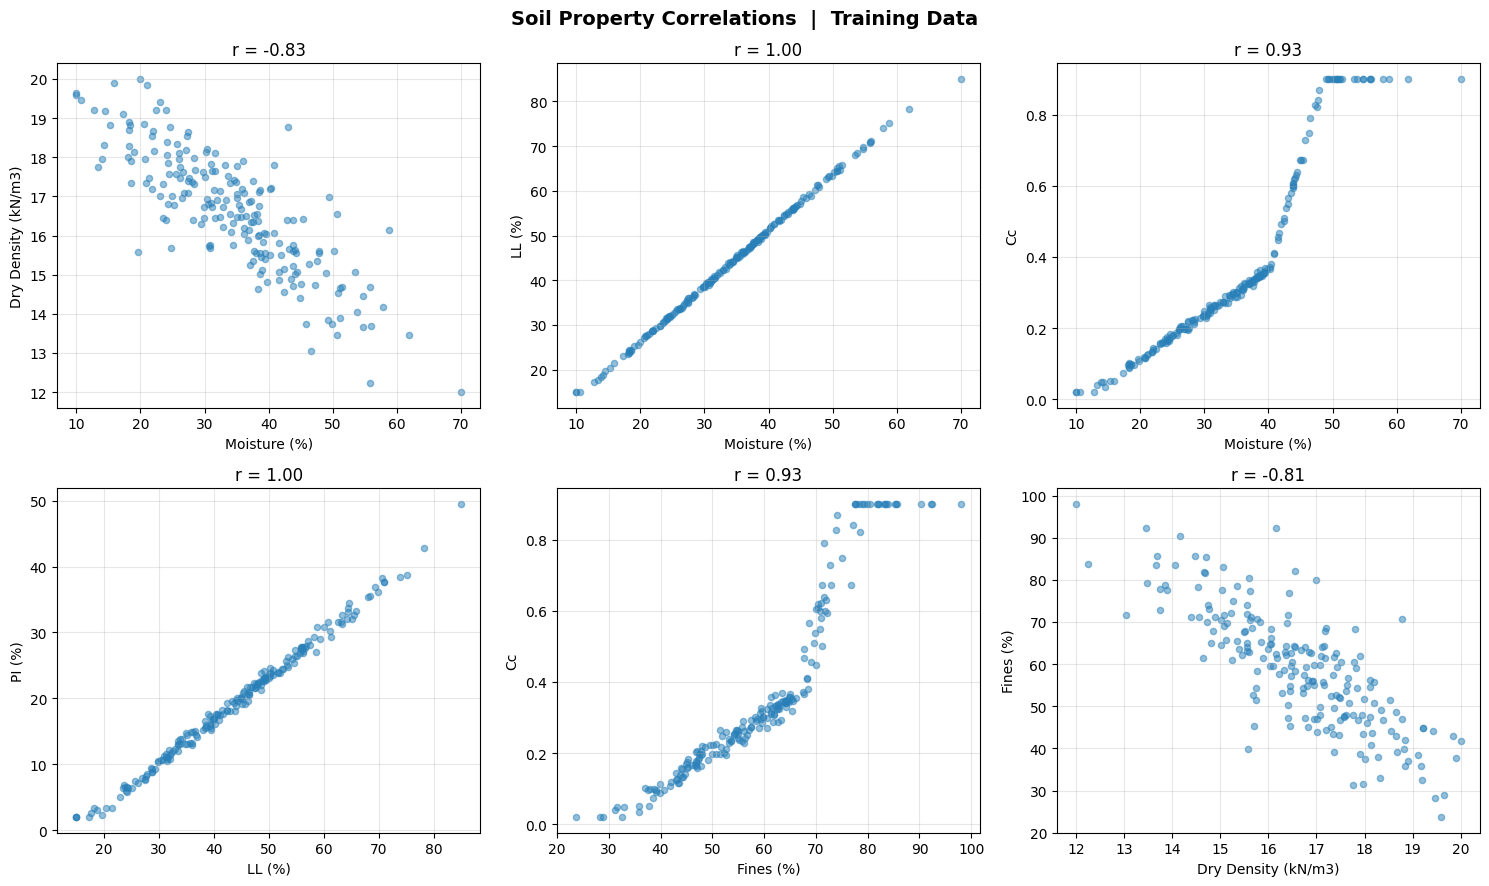

In [3]:
# ───────────────────────────────────────────────────────
# VISUALIZE PROPERTY CORRELATIONS
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
pairs = [(0, 1), (0, 2), (0, 5), (2, 3), (4, 5), (1, 4)]

for ax, (i, j) in zip(axes.flatten(), pairs):
    ax.scatter(soil_data[:, i], soil_data[:, j], alpha=0.5, s=20, color='#2980b9')
    corr = np.corrcoef(soil_data[:, i], soil_data[:, j])[0, 1]
    ax.set_xlabel(feature_names[i])
    ax.set_ylabel(feature_names[j])
    ax.set_title(f'r = {corr:.2f}')
    ax.grid(True, alpha=0.3)

fig.suptitle('Soil Property Correlations  |  Training Data', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [4]:
# ───────────────────────────────────────────────────────
# PREPARE TRAINING DATA
# ───────────────────────────────────────────────────────

scaler = StandardScaler()
data_scaled = scaler.fit_transform(soil_data)

X_tensor = torch.FloatTensor(data_scaled)
train_ds = TensorDataset(X_tensor, X_tensor)
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)

input_dim = data_scaled.shape[1]
print(f"Input dimension: {input_dim}")
print(f"Samples: {len(X_tensor)}")

Input dimension: 6
Samples: 200


## Part 2: VAE Theory

A VAE differs from a standard autoencoder in two key ways:

### 1. The encoder outputs a distribution, not a point
Instead of encoding $x$ to a fixed vector $z$, we encode to parameters of a distribution:
$$\text{Encoder}(x) \rightarrow (\mu, \log \sigma^2)$$

### 2. The reparameterization trick
To sample from $\mathcal{N}(\mu, \sigma^2)$ while allowing backpropagation:
$$z = \mu + \sigma \cdot \epsilon, \quad \epsilon \sim \mathcal{N}(0, 1)$$

### 3. The ELBO loss
$$\mathcal{L} = \underbrace{\|x - \hat{x}\|^2}_{\text{Reconstruction}} + \beta \cdot \underbrace{D_{KL}(q(z|x) \| p(z))}_{\text{KL Divergence}}$$

The KL term regularizes the latent space to be close to $\mathcal{N}(0, I)$,
ensuring smooth interpolation and meaningful sampling.

---

In [5]:
# ───────────────────────────────────────────────────────
# VAE ARCHITECTURE
# ───────────────────────────────────────────────────────

class SoilVAE(nn.Module):
    """Variational Autoencoder for soil property generation."""
    
    def __init__(self, input_dim=6, latent_dim=2, hidden_dim=32):
        super().__init__()
        self.latent_dim = latent_dim
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )
        self.fc_mu     = nn.Linear(hidden_dim, latent_dim)  # mean
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)  # log variance
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
        )
    
    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar
    
    def reparameterize(self, mu, logvar):
        """Sample z using the reparameterization trick."""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)   # sample from N(0, 1)
        return mu + eps * std
    
    def decode(self, z):
        return self.decoder(z)
    
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar, z

def vae_loss(x, x_hat, mu, logvar, beta=1.0):
    """
    ELBO loss = Reconstruction + beta * KL divergence.
    
    KL(N(mu, sigma) || N(0, 1)) = -0.5 * sum(1 + log(sigma^2) - mu^2 - sigma^2)
    """
    recon_loss = F.mse_loss(x_hat, x, reduction='sum') / x.shape[0]
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.shape[0]
    return recon_loss + beta * kl_loss, recon_loss, kl_loss

model = SoilVAE(input_dim=input_dim, latent_dim=2, hidden_dim=32)
n_params = sum(p.numel() for p in model.parameters())
print(f"VAE parameters: {n_params:,}")
print(f"\nArchitecture:\n{model}")

VAE parameters: 2,762

Architecture:
SoilVAE(
  (encoder): Sequential(
    (0): Linear(in_features=6, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=32, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=32, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=6, bias=True)
  )
)


In [6]:
# ───────────────────────────────────────────────────────
# TRAIN THE VAE
# ───────────────────────────────────────────────────────

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 300
beta = 0.5  # weight for KL term (beta-VAE)

history = {'total': [], 'recon': [], 'kl': []}

for epoch in range(epochs):
    model.train()
    epoch_total, epoch_recon, epoch_kl = 0, 0, 0
    
    for xb, _ in train_dl:
        x_hat, mu, logvar, z = model(xb)
        total, recon, kl = vae_loss(xb, x_hat, mu, logvar, beta=beta)
        
        optimizer.zero_grad()
        total.backward()
        optimizer.step()
        
        epoch_total += total.item()
        epoch_recon += recon.item()
        epoch_kl += kl.item()
    
    n_batches = len(train_dl)
    history['total'].append(epoch_total / n_batches)
    history['recon'].append(epoch_recon / n_batches)
    history['kl'].append(epoch_kl / n_batches)
    
    if (epoch + 1) % 75 == 0:
        print(f"Epoch {epoch+1:3d}/{epochs} | Total: {history['total'][-1]:.4f}  "
              f"Recon: {history['recon'][-1]:.4f}  KL: {history['kl'][-1]:.4f}")

Epoch  75/300 | Total: 1.6360  Recon: 0.7451  KL: 1.7817


Epoch 150/300 | Total: 1.3883  Recon: 0.6441  KL: 1.4885


Epoch 225/300 | Total: 1.4226  Recon: 0.5565  KL: 1.7322


Epoch 300/300 | Total: 1.4131  Recon: 0.6257  KL: 1.5748


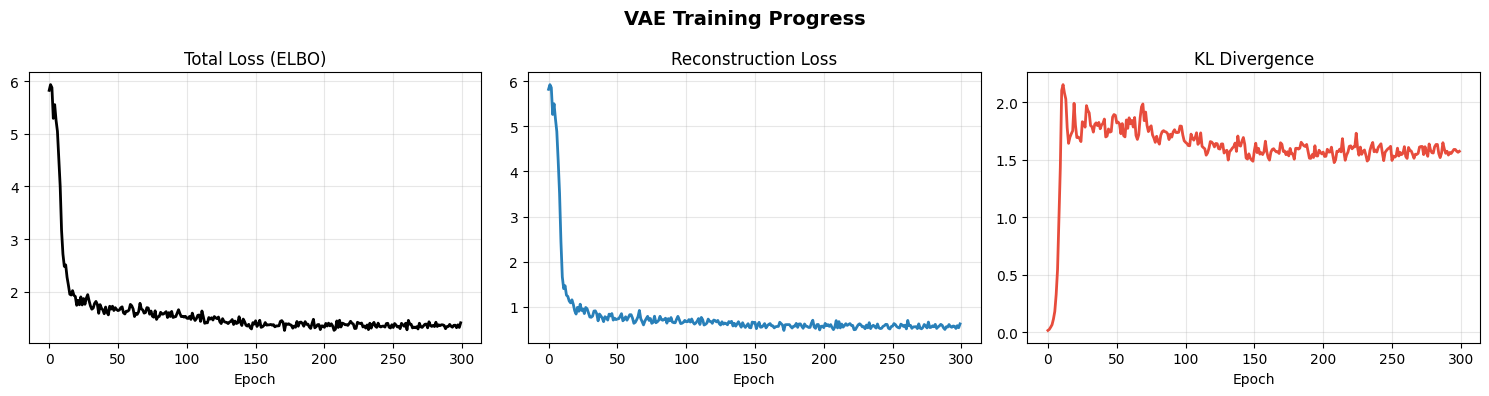

In [7]:
# ───────────────────────────────────────────────────────
# TRAINING CURVES: RECONSTRUCTION vs KL DIVERGENCE
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history['total'], linewidth=2, color='black')
axes[0].set_title('Total Loss (ELBO)')
axes[0].set_xlabel('Epoch')
axes[0].grid(True, alpha=0.3)

axes[1].plot(history['recon'], linewidth=2, color='#2980b9')
axes[1].set_title('Reconstruction Loss')
axes[1].set_xlabel('Epoch')
axes[1].grid(True, alpha=0.3)

axes[2].plot(history['kl'], linewidth=2, color='#e74c3c')
axes[2].set_title('KL Divergence')
axes[2].set_xlabel('Epoch')
axes[2].grid(True, alpha=0.3)

fig.suptitle('VAE Training Progress', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Part 3: Generating New Soil Profiles

The power of a VAE: sample $z \sim \mathcal{N}(0, I)$ and decode to get
a **new, realistic** soil profile that respects the learned correlations.

---

In [8]:
# ───────────────────────────────────────────────────────
# GENERATE NEW SOIL PROFILES BY SAMPLING
# ───────────────────────────────────────────────────────

model.eval()

# Sample from the prior N(0, I)
n_generated = 500
with torch.no_grad():
    z_sample = torch.randn(n_generated, 2)
    generated_scaled = model.decode(z_sample).numpy()

# Inverse transform to original scale
generated = scaler.inverse_transform(generated_scaled)

print(f"Generated {n_generated} new soil profiles")
print(f"\nComparison of statistics:")
print(f"{'Property':<22s} {'Real Mean':>10s} {'Gen Mean':>10s} {'Real Std':>10s} {'Gen Std':>10s}")
print("-" * 64)
for i, name in enumerate(feature_names):
    print(f"{name:<22s} {soil_data[:, i].mean():>10.2f} {generated[:, i].mean():>10.2f} "
          f"{soil_data[:, i].std():>10.2f} {generated[:, i].std():>10.2f}")

Generated 500 new soil profiles

Comparison of statistics:
Property                Real Mean   Gen Mean   Real Std    Gen Std
----------------------------------------------------------------
Moisture (%)                34.27      34.63      11.08      10.66
Dry Density (kN/m3)         16.63      16.57       1.53       1.29
LL (%)                      44.06      44.48      13.79      13.29
PI (%)                      19.48      19.79       9.11       8.77
Fines (%)                   58.92      59.42      14.01      13.40
Cc                           0.36       0.37       0.25       0.24


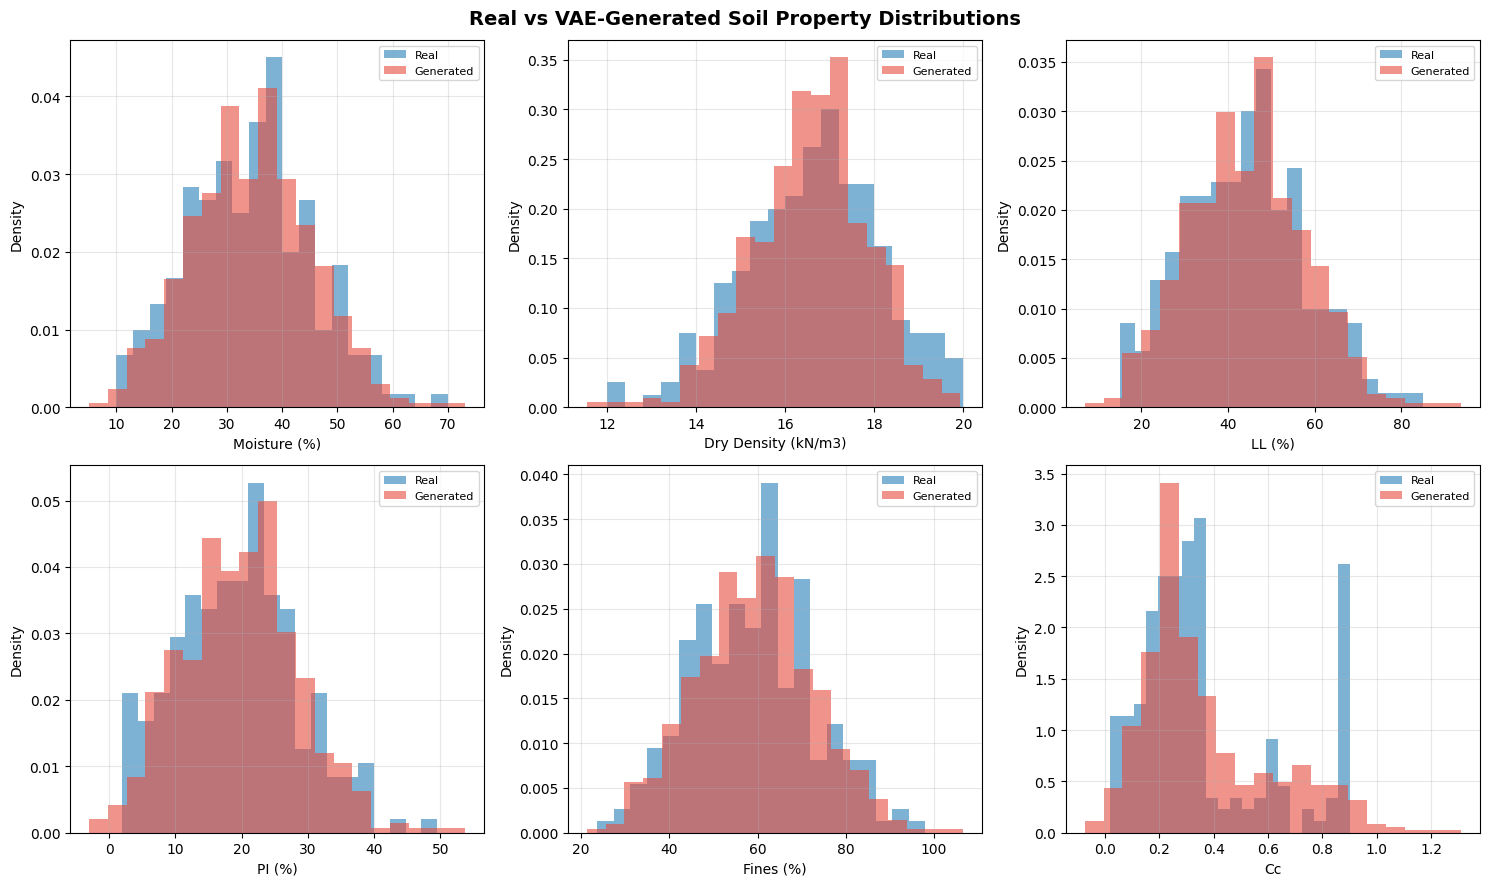

In [9]:
# ───────────────────────────────────────────────────────
# COMPARE GENERATED vs REAL DISTRIBUTIONS
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, i in zip(axes.flatten(), range(len(feature_names))):
    ax.hist(soil_data[:, i], bins=20, alpha=0.6, color='#2980b9', density=True, label='Real')
    ax.hist(generated[:, i], bins=20, alpha=0.6, color='#e74c3c', density=True, label='Generated')
    ax.set_xlabel(feature_names[i])
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

fig.suptitle('Real vs VAE-Generated Soil Property Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

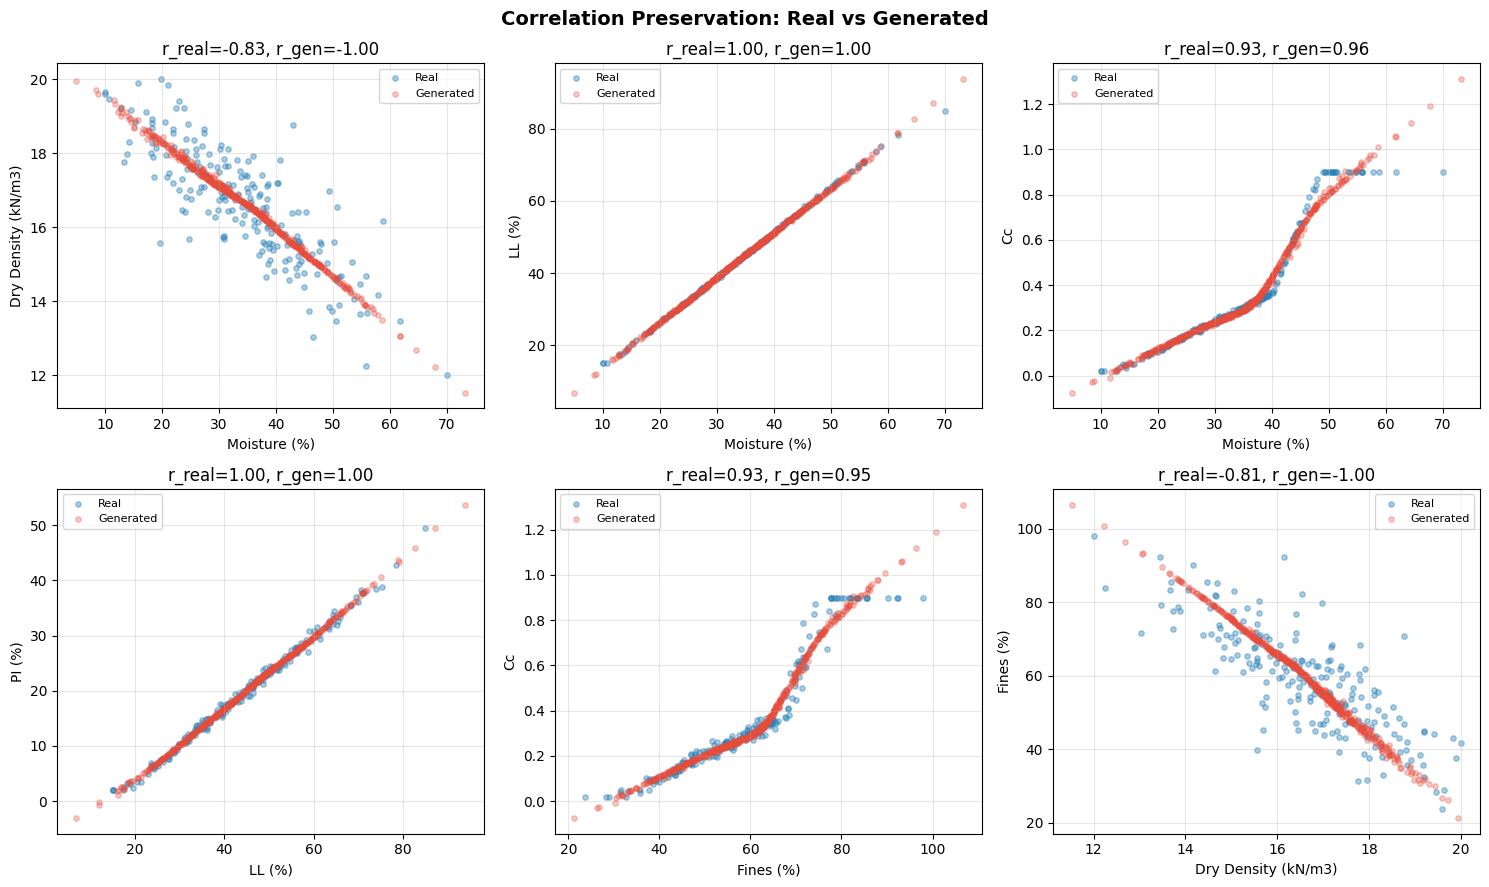

In [10]:
# ───────────────────────────────────────────────────────
# COMPARE CORRELATIONS: REAL vs GENERATED
# ───────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
pairs = [(0, 1), (0, 2), (0, 5), (2, 3), (4, 5), (1, 4)]

for ax, (i, j) in zip(axes.flatten(), pairs):
    ax.scatter(soil_data[:, i], soil_data[:, j], alpha=0.4, s=15, color='#2980b9', label='Real')
    ax.scatter(generated[:, i], generated[:, j], alpha=0.3, s=15, color='#e74c3c', label='Generated')
    
    corr_real = np.corrcoef(soil_data[:, i], soil_data[:, j])[0, 1]
    corr_gen  = np.corrcoef(generated[:, i], generated[:, j])[0, 1]
    
    ax.set_xlabel(feature_names[i])
    ax.set_ylabel(feature_names[j])
    ax.set_title(f'r_real={corr_real:.2f}, r_gen={corr_gen:.2f}')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

fig.suptitle('Correlation Preservation: Real vs Generated', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Part 4: Latent Space Exploration

With a 2D latent space, we can:
- Visualize where real samples fall
- Interpolate between soil types
- Understand what each latent dimension encodes

---

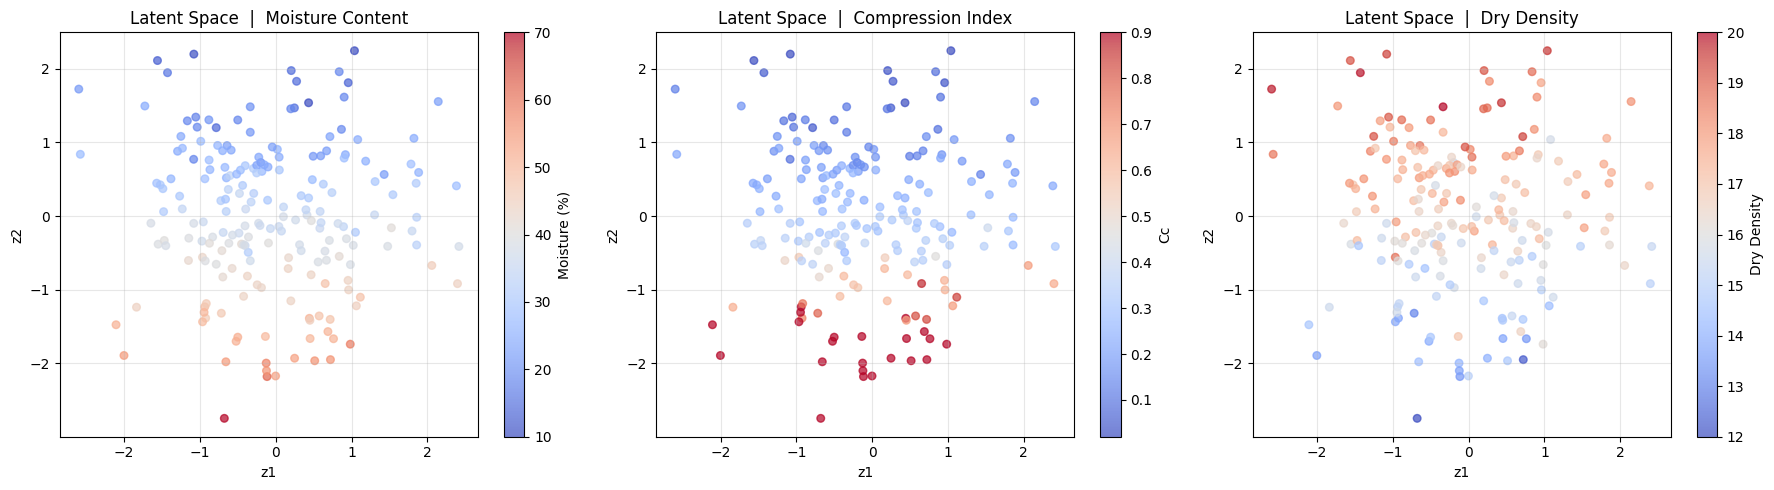

In [11]:
# ───────────────────────────────────────────────────────
# LATENT SPACE VISUALIZATION
# ───────────────────────────────────────────────────────

model.eval()
with torch.no_grad():
    _, _, _, z_encoded = model(X_tensor)
    z_np = z_encoded.numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Color by moisture content
sc0 = axes[0].scatter(z_np[:, 0], z_np[:, 1], c=soil_data[:, 0], cmap='coolwarm', alpha=0.7, s=30)
plt.colorbar(sc0, ax=axes[0], label='Moisture (%)')
axes[0].set_title('Latent Space  |  Moisture Content')
axes[0].set_xlabel('z1')
axes[0].set_ylabel('z2')
axes[0].grid(True, alpha=0.3)

# Color by Cc
sc1 = axes[1].scatter(z_np[:, 0], z_np[:, 1], c=soil_data[:, 5], cmap='coolwarm', alpha=0.7, s=30)
plt.colorbar(sc1, ax=axes[1], label='Cc')
axes[1].set_title('Latent Space  |  Compression Index')
axes[1].set_xlabel('z1')
axes[1].set_ylabel('z2')
axes[1].grid(True, alpha=0.3)

# Color by dry density
sc2 = axes[2].scatter(z_np[:, 0], z_np[:, 1], c=soil_data[:, 1], cmap='coolwarm', alpha=0.7, s=30)
plt.colorbar(sc2, ax=axes[2], label='Dry Density')
axes[2].set_title('Latent Space  |  Dry Density')
axes[2].set_xlabel('z1')
axes[2].set_ylabel('z2')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

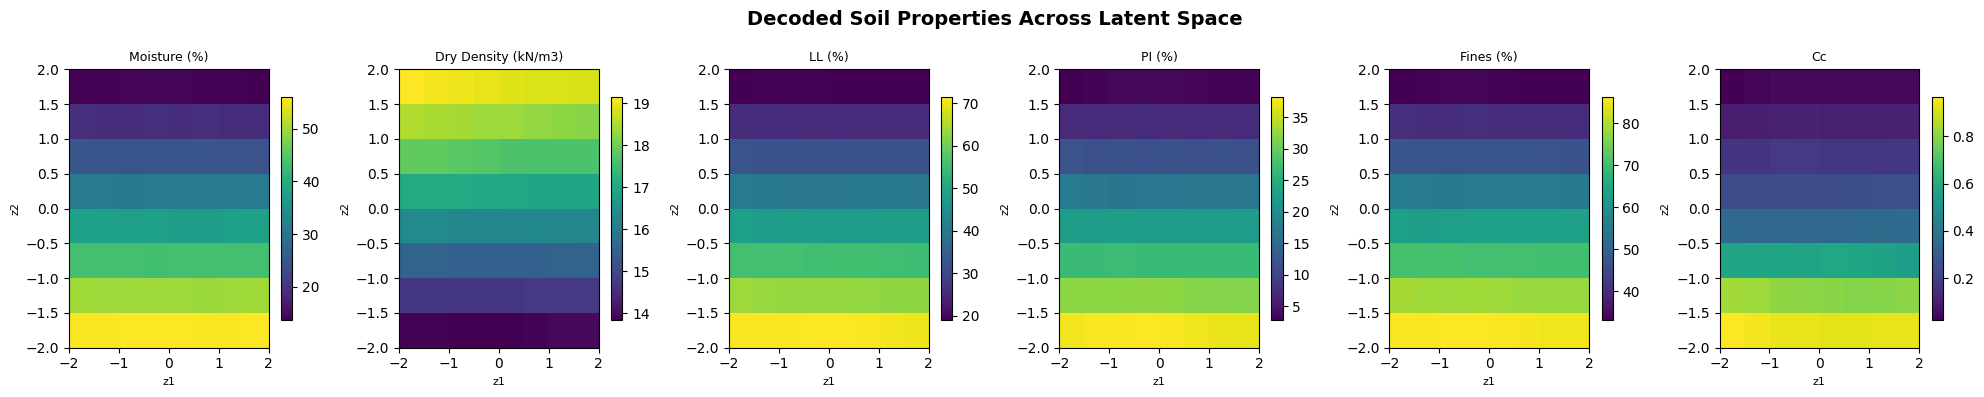

In [12]:
# ───────────────────────────────────────────────────────
# LATENT SPACE INTERPOLATION
# ───────────────────────────────────────────────────────
# Walk through latent space and decode soil profiles

n_grid = 8
z1_range = np.linspace(-2, 2, n_grid)
z2_range = np.linspace(-2, 2, n_grid)

fig, axes = plt.subplots(1, 6, figsize=(20, 4))

for feat_idx, ax in enumerate(axes):
    grid = np.zeros((n_grid, n_grid))
    for i, z1 in enumerate(z1_range):
        for j, z2 in enumerate(z2_range):
            with torch.no_grad():
                z = torch.FloatTensor([[z1, z2]])
                decoded = model.decode(z).numpy()
                decoded_orig = scaler.inverse_transform(decoded)
                grid[j, i] = decoded_orig[0, feat_idx]
    
    im = ax.imshow(grid, extent=[-2, 2, -2, 2], origin='lower', aspect='auto', cmap='viridis')
    ax.set_title(feature_names[feat_idx], fontsize=9)
    ax.set_xlabel('z1', fontsize=8)
    ax.set_ylabel('z2', fontsize=8)
    plt.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle('Decoded Soil Properties Across Latent Space', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## Practice Exercises

Try these exercises to deepen your understanding:

```python
# Exercise 1: Beta tuning
# Train VAEs with beta = 0.1, 1.0, 5.0 and compare.
# Higher beta -> more regularized latent space but worse reconstruction.

# Exercise 2: Higher latent dimension
# Try latent_dim = 4 or 8. Compare generated sample quality.
# You cannot visualize 4D directly, but can compare distributions.

# Exercise 3: Conditional VAE
# Add soil type as a condition: encode (x, soil_type) and decode (z, soil_type).
# This lets you generate clay-like or sand-like profiles on demand.

# Exercise 4: Reliability analysis
# Generate 10,000 profiles and compute bearing capacity for each.
# Plot the distribution and estimate failure probability.
```

---

## Key Takeaways

1. **VAEs encode inputs as distributions** (mean + variance), not fixed points
2. **The reparameterization trick** enables gradient-based training through sampling
3. **KL divergence regularization** ensures smooth, meaningful latent spaces
4. **Generated soil profiles** preserve the correlations in the training data
5. **Latent space interpolation** reveals continuous transitions between soil types

---

## How This Connects

| ML Concept | Geotechnical Application |
|-----------|------------------------|
| Generative model | Creating synthetic soil profiles for Monte Carlo analysis |
| Correlation preservation | Generating physically consistent property combinations |
| Latent space | Understanding hidden factors driving soil behavior |
| KL regularization | Ensuring generated profiles are not just copies |
| Beta tuning | Controlling diversity vs fidelity of generated samples |